# Stage 6 ? findings and robustness

This notebook reads the reviewed Stage 6 aggregates and figures. It does not call a model, alter the primary experiment, or rerun sensitivity episodes. The experimental unit is one matched series-window block; there are three selected blocks. The 756 policy-days are repeated observations inside those blocks, not independent replications. The primary window had uncertain prior manual outcome use, so it is not described as pristine or unseen.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
RESULTS = ROOT / "docs/results/stage6"
ASSETS = ROOT / "docs/assets/stage6"
read = lambda name: pd.read_csv(RESULTS / f"{name}.csv")
contrasts = read("paired_shock_contrasts")
scenarios = read("per_scenario_summaries")
recovery = read("recovery")
reliability = read("llm_episode_reliability_costs")
sensitivity = read("baseline_elasticity_summary")
assert len(read("episode_metrics")) == 36
assert len(contrasts) == 18 and len(read("phase_summaries")) == 108
assert len(read("action_traces")) == 756 and len(sensitivity) == 72
print("Reviewed Stage 6 outputs loaded; no model or simulator calls.")

Reviewed Stage 6 outputs loaded; no model or simulator calls.


## Matched contribution comparisons

For each shock and selected block, the primary comparison is LLM with fallback minus the matched adaptive policy. The control-adjusted effect subtracts the same policy contrast in the control episode. These simulator contrasts describe this frozen set of three blocks only.

In [2]:
primary = contrasts.query("comparator == 'adaptive'").copy()
primary[["store_id", "product_id", "scenario", "contribution_difference", "relative_gain_percent", "control_adjusted_contribution", "fill_rate_difference_pp"]]

,store_id,product_id,scenario,contribution_difference,relative_gain_percent,control_adjusted_contribution,fill_rate_difference_pp
0,S001,P0001,demand_surge,-3801.866250,-6.899139,-46.383750,1.317716
1,S001,P0001,demand_decline,-2815.890000,-7.020077,939.592500,0.000000
2,S001,P0001,delivery_disruption,1411.659375,3.315697,5167.141875,7.830245
6,S004,P0006,demand_surge,-3014.686416,-7.771957,-1364.909104,-0.598683
7,S004,P0006,demand_decline,-1404.306160,-5.007612,245.471152,-1.014763
8,S004,P0006,delivery_disruption,261.557552,0.883365,1911.334864,6.905594
12,S003,P0016,demand_surge,-4695.244155,-5.275281,481.187535,0.000000
13,S003,P0016,demand_decline,-5002.069491,-7.357549,174.362199,0.000000
14,S003,P0016,delivery_disruption,-4376.439444,-5.803377,799.992246,2.490726


In [3]:
scenarios.query("comparator == 'adaptive'")[["scenario", "matched_blocks", "raw_mean", "raw_minimum", "raw_maximum", "control_adjusted_mean", "control_adjusted_positive", "control_adjusted_negative", "mean_control_adjusted_fill_rate_pp"]]

,scenario,matched_blocks,raw_mean,raw_minimum,raw_maximum,control_adjusted_mean,control_adjusted_positive,control_adjusted_negative,mean_control_adjusted_fill_rate_pp
0,demand_surge,3,-3837.265607,-4695.244155,-3014.686416,-310.035106,1,2,0.527993
1,demand_decline,3,-3074.088550,-5002.069491,-1404.306160,453.141950,3,0,-0.049939
2,delivery_disruption,3,-901.074172,-4376.439444,1411.659375,2626.156328,3,0,6.030504


Across the nine adaptive shock comparisons, raw contribution was higher for the LLM policy in 2 and lower in 7. The control-adjusted contribution was positive in 7 and negative in 2. These tell different stories: raw shock rankings are affected by each policy's control performance. The average control-adjusted effect is negative for surge (about ?310 dataset monetary units), positive for decline (about +453), and positive for delivery disruption (about +2,626). Each average equally weights only three selected blocks.

## Recovery and operating reliability

Recovery means three consecutive post-shock days with zero lost sales and closing inventory within the frozen band around the same policy's control. The latest possible recovery start is day 19. Cases not meeting the full rule are right-censored at day 21; this is operational normalization, not cumulative profit recovery.

In [4]:
recovery.groupby("policy").agg(episodes=("recovered", "size"), recovered=("recovered", "sum"), censored=("right_censored", "sum"))

,episodes,recovered,censored
policy,,,
adaptive,9,3,6
fixed,9,9,0
llm_with_fallback,9,9,0


In [5]:
llm = read("action_traces").query("policy == 'llm_with_fallback'")
print({"opportunities": len(llm), "first_pass_valid": int((~llm.repair_attempted).sum()),
       "successful_repairs": int((llm.repair_attempted & ~llm.fallback_used).sum()),
       "fallback_days_retained": int(llm.fallback_used.sum()),
       "invalid_raw_responses": int(llm.invalid_responses.sum())})
reliability[["matrix_index", "primary_attempts", "repair_attempts", "physical_attempts", "cost_credits", "median_latency_seconds", "p95_latency_seconds"]]

{'opportunities': 252, 'first_pass_valid': 108, 'successful_repairs': 127, 'fallback_days_retained': 17, 'invalid_raw_responses': 161}


,matrix_index,primary_attempts,repair_attempts,physical_attempts,cost_credits,median_latency_seconds,p95_latency_seconds
0,2,21,8,29,0.018338,1.581380,3.150888
1,5,21,10,31,0.019654,1.445979,1.964028
2,8,21,7,28,0.017687,1.450709,4.582031
3,11,21,9,30,0.018875,1.335013,2.580508
4,14,21,15,36,0.022859,1.458501,2.026554
5,17,21,15,36,0.023198,1.542198,2.610762
6,20,21,13,34,0.021435,1.451243,3.322077
7,23,21,14,35,0.022069,1.537200,2.414072
8,26,21,16,37,0.023804,1.335856,1.945686
9,29,21,12,33,0.021207,1.448913,3.090543


The primary operational policy retains all 17 fallback days. Only 108 of 252 LLM decisions were valid on the first response; 127 were repaired successfully and 17 used the adaptive fallback. The 161 invalid raw responses were cash-affordability errors. Request costs are gateway credits, separate from simulator monetary units; project accounting retains earlier uncertain charges.

## Baseline-only elasticity sensitivity

The analysis reused 24 existing primary baseline episodes at elasticity 1.5 and independently replayed 48 free episodes at 0.75 and 2.25 (1,008 new policy-days). Only the prepared elasticity assumption changed. This evaluates simulator sensitivity for fixed and adaptive baselines; it is not an LLM robustness test.

In [6]:
sensitivity.groupby(["elasticity", "policy", "provenance"]).agg(episodes=("status", "size"),
    mean_contribution=("contribution", "mean"), mean_fill_rate=("fill_rate", "mean"),
    model_calls=("model_calls", "sum")).reset_index()

,elasticity,policy,provenance,episodes,mean_contribution,mean_fill_rate,model_calls
0,0.75,adaptive,new_baseline_sensitivity,12,51969.428777,0.969066,0
1,0.75,fixed,new_baseline_sensitivity,12,50607.472086,0.963237,0
2,1.50,adaptive,reused_primary,12,51657.232315,0.974632,0
3,1.50,fixed,reused_primary,12,50607.472086,0.963237,0
4,2.25,adaptive,new_baseline_sensitivity,12,51291.450909,0.979221,0
5,2.25,fixed,new_baseline_sensitivity,12,50607.472086,0.963237,0


## Native evidence and diagnostics

Native benchmark families remain separate because their score units and task designs differ. Stage 3 has 14 validated tasks, one retained ICBE validity failure and four deferred Retail tasks. The native figures below show coverage and dataset-specific accuracy; they are not a pooled ranking. Diagnostic panels are post-outcome illustrations, while the complete condition-level tables and traces remain available.

In [7]:
coverage = read("native_task_coverage")
coverage[[column for column in ("task", "status", "native_accuracy_unit", "native_correct_units", "native_scored_units", "accuracy") if column in coverage.columns]]

,task,status
0,retail:dynamic_middle,deferred
1,retail:dynamic_hard,deferred
2,retail:still_middle,deferred
3,retail:still_hard,deferred
4,firm:FinCode,validated_complete
5,firm:CodeFinQA,validated_complete
6,firm:CodeTAT-QA,validated_complete
7,firm:SEC-NUM,validated_complete
8,firm:TAT-QA,validated_complete
9,firm:ConvFinQA,validated_complete


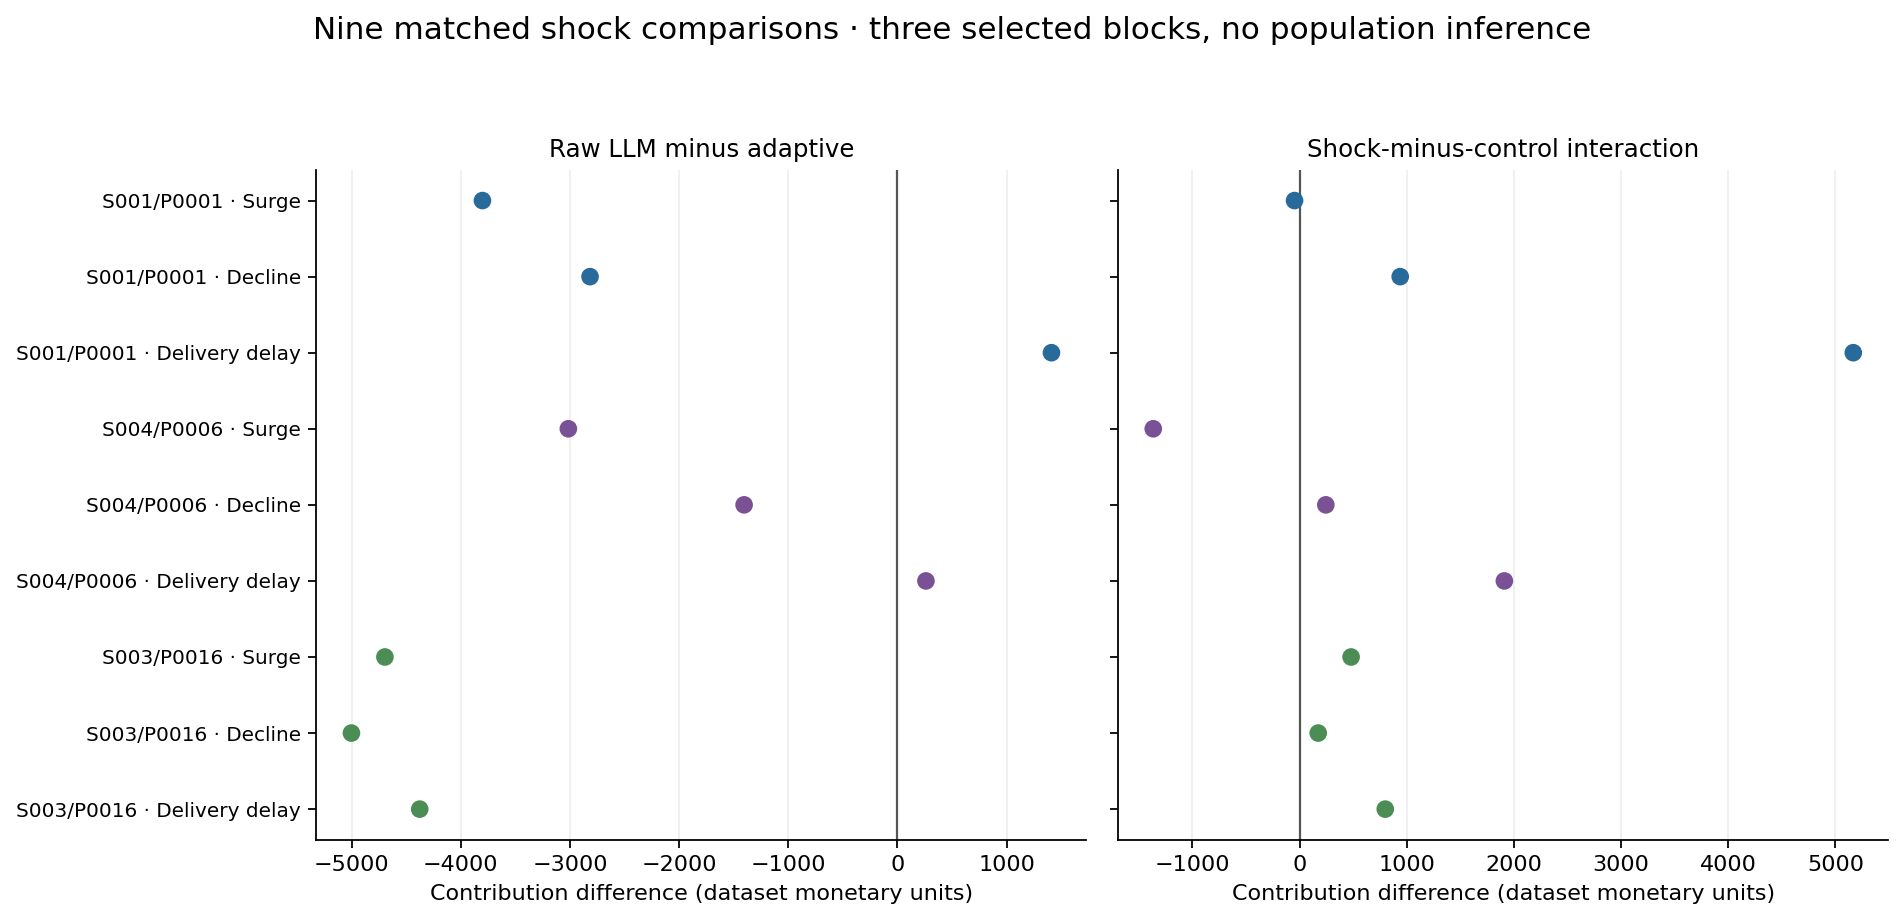

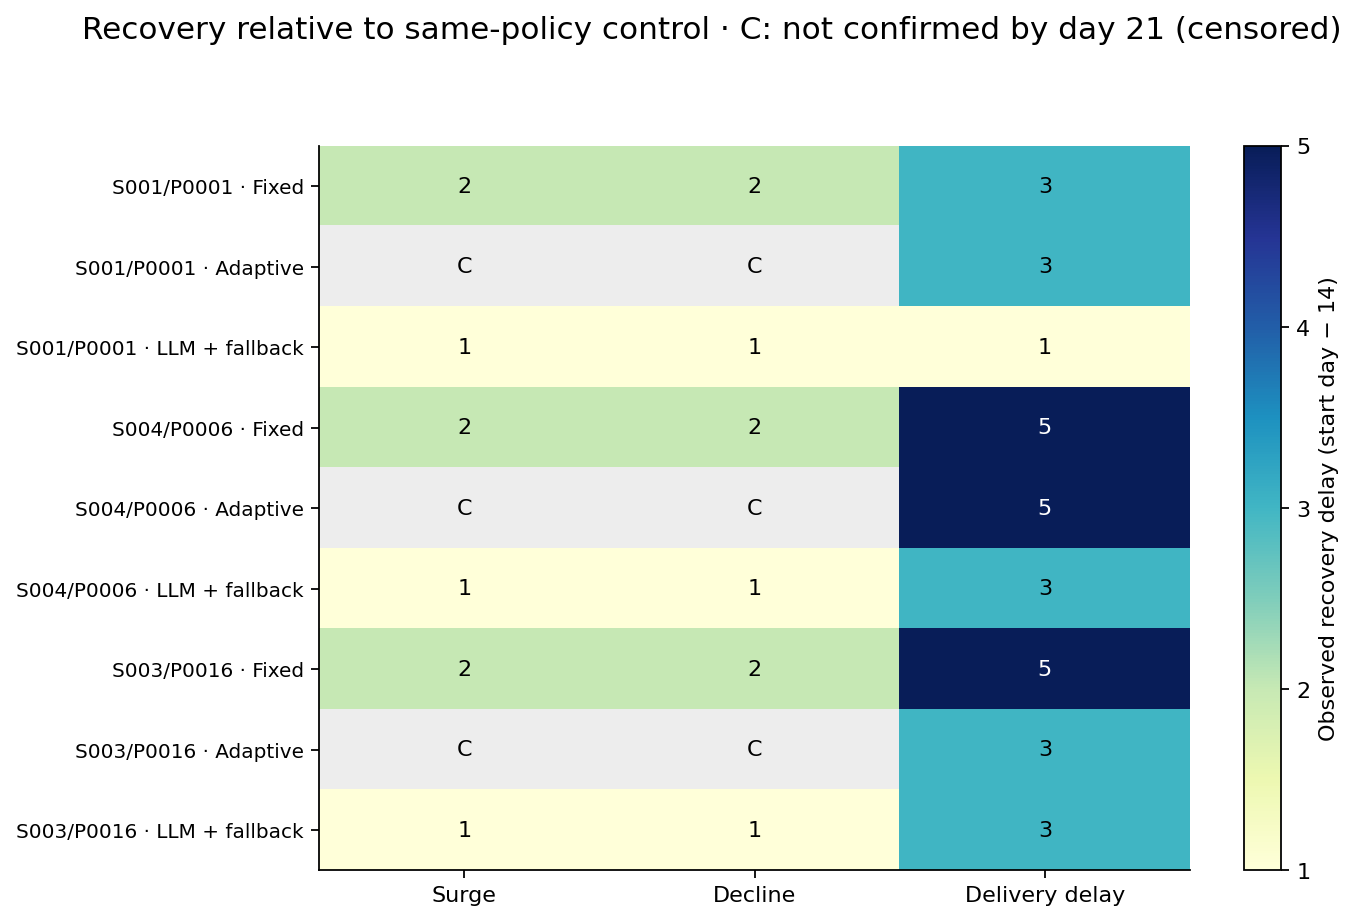

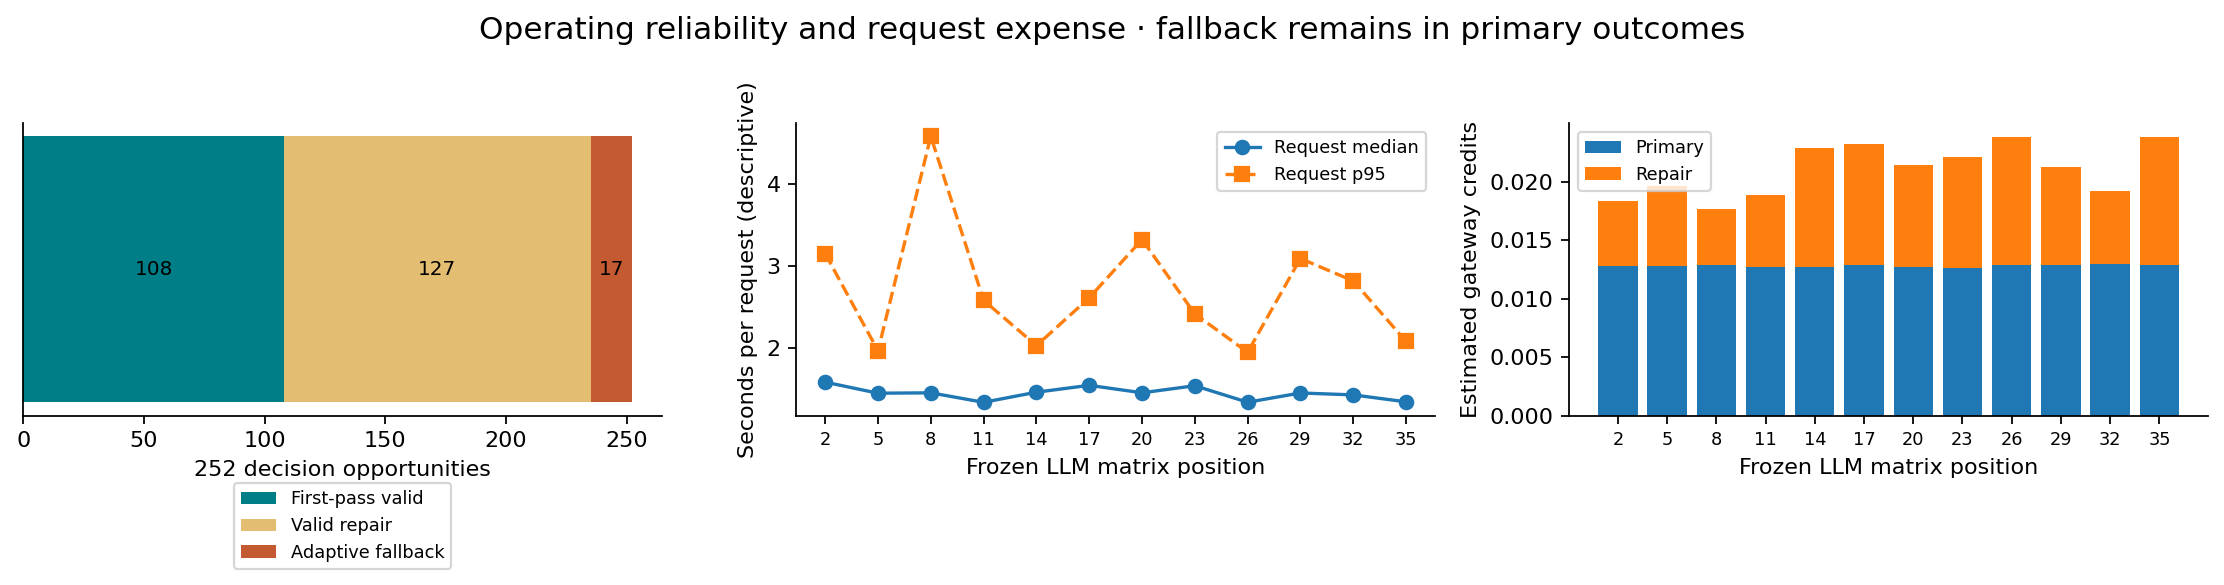

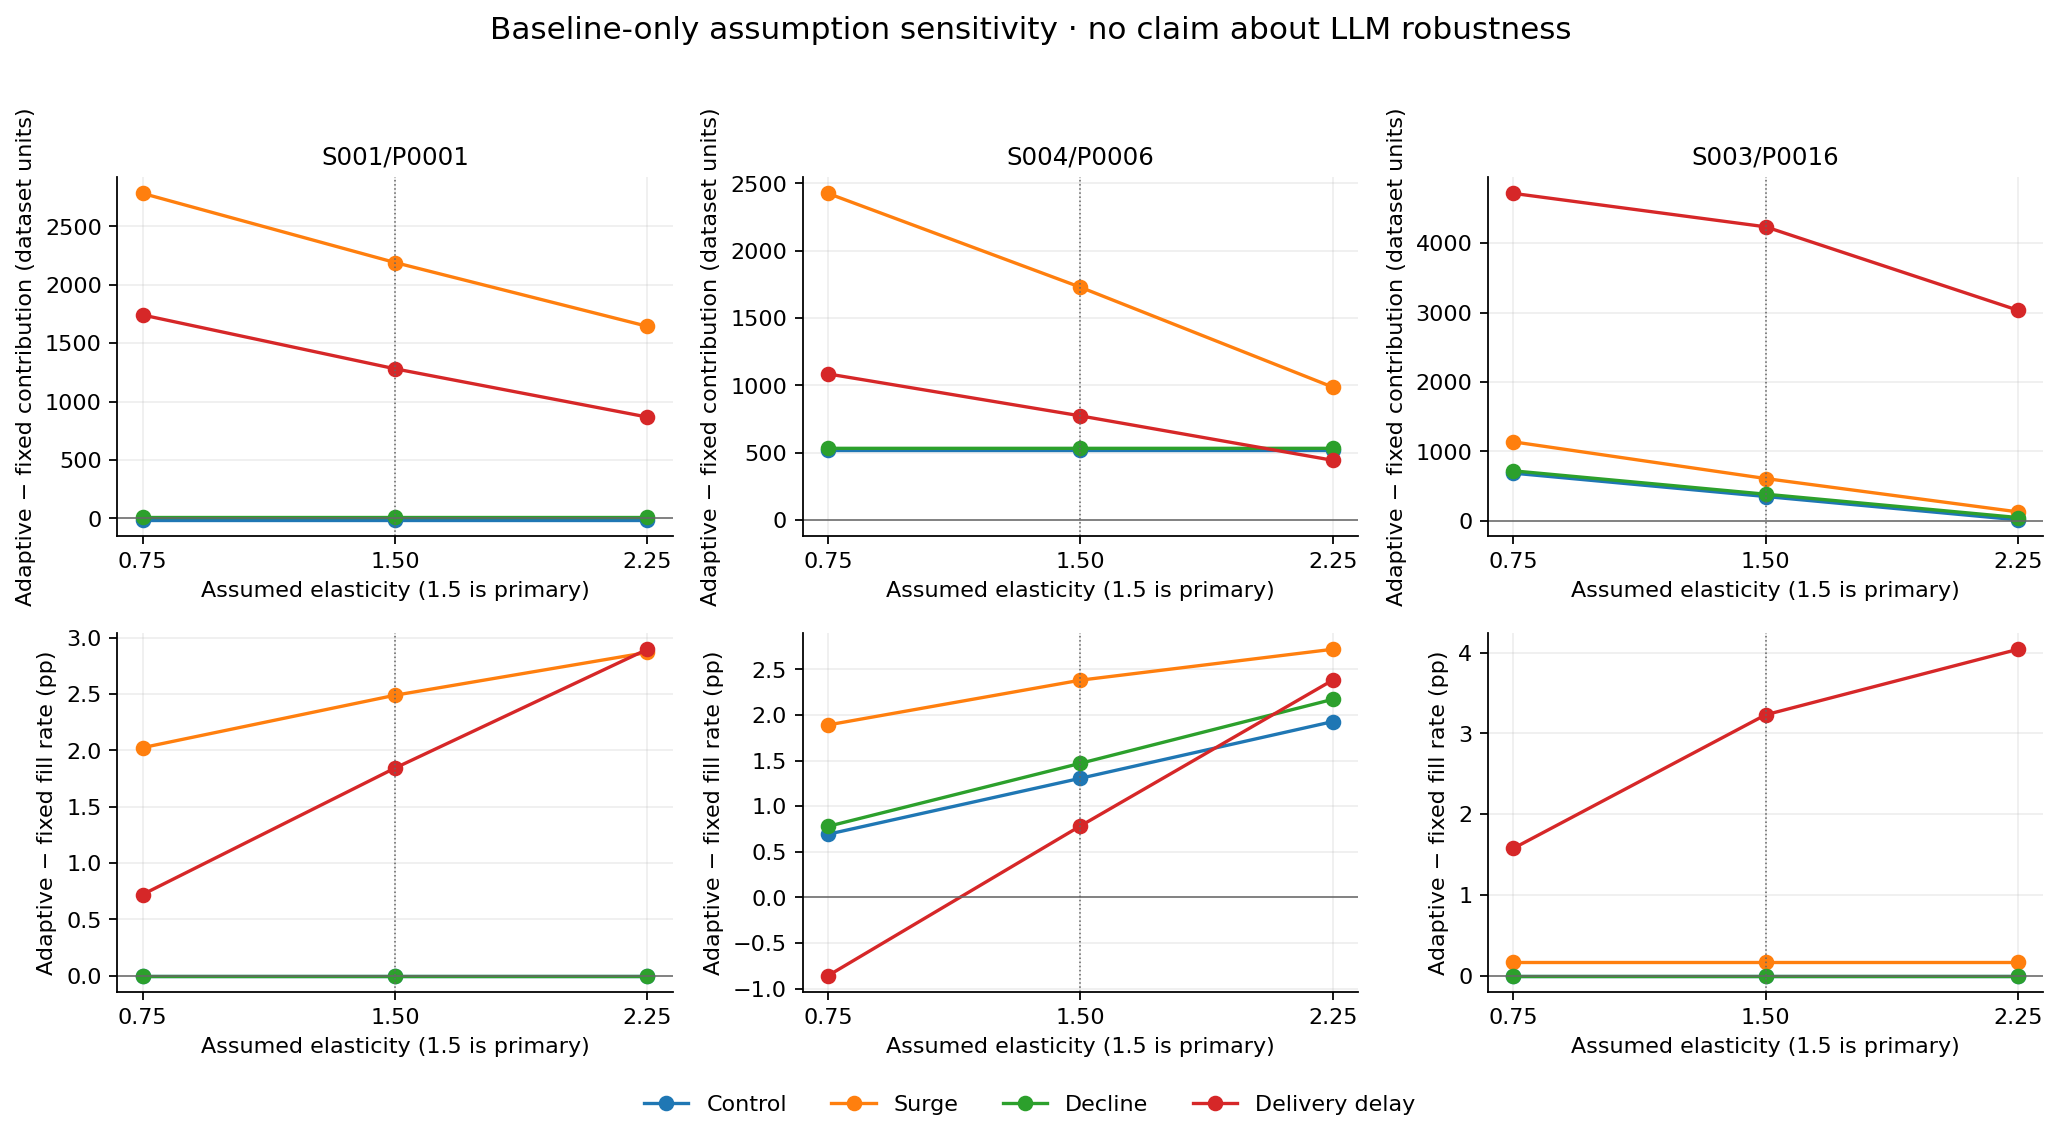

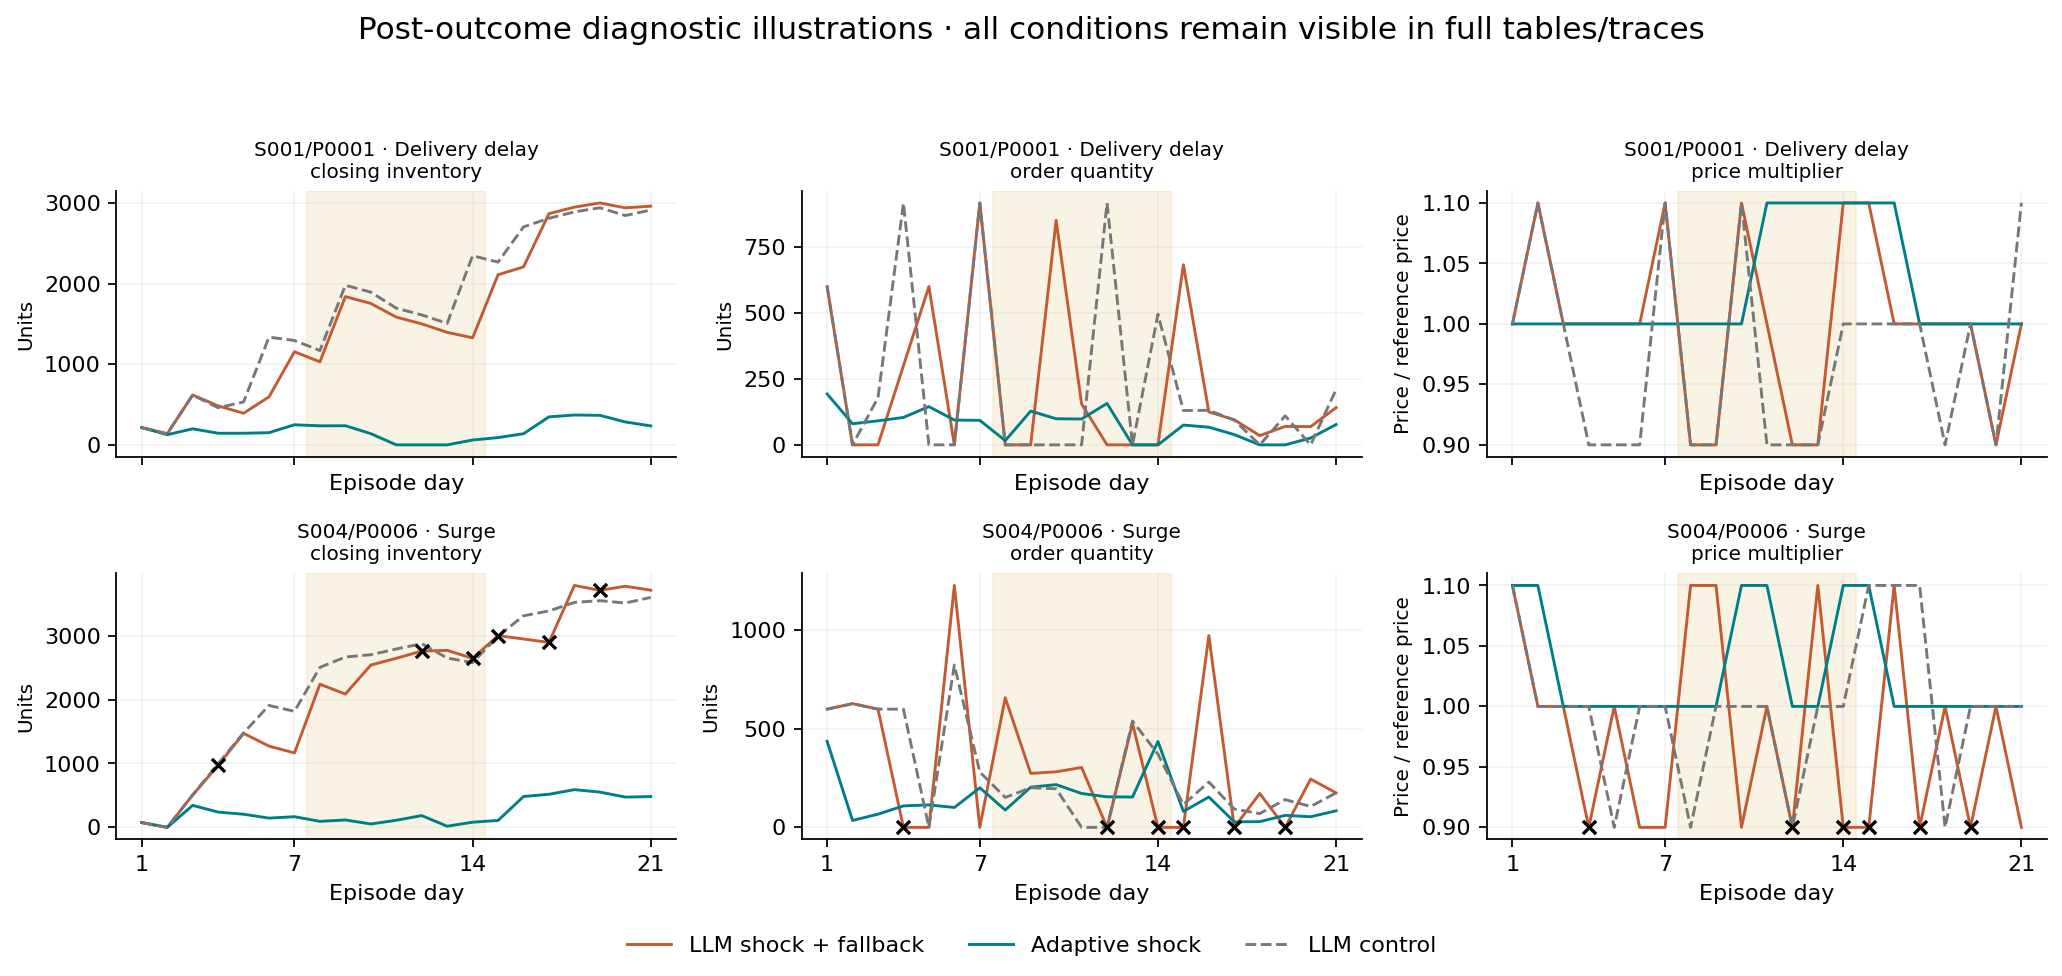

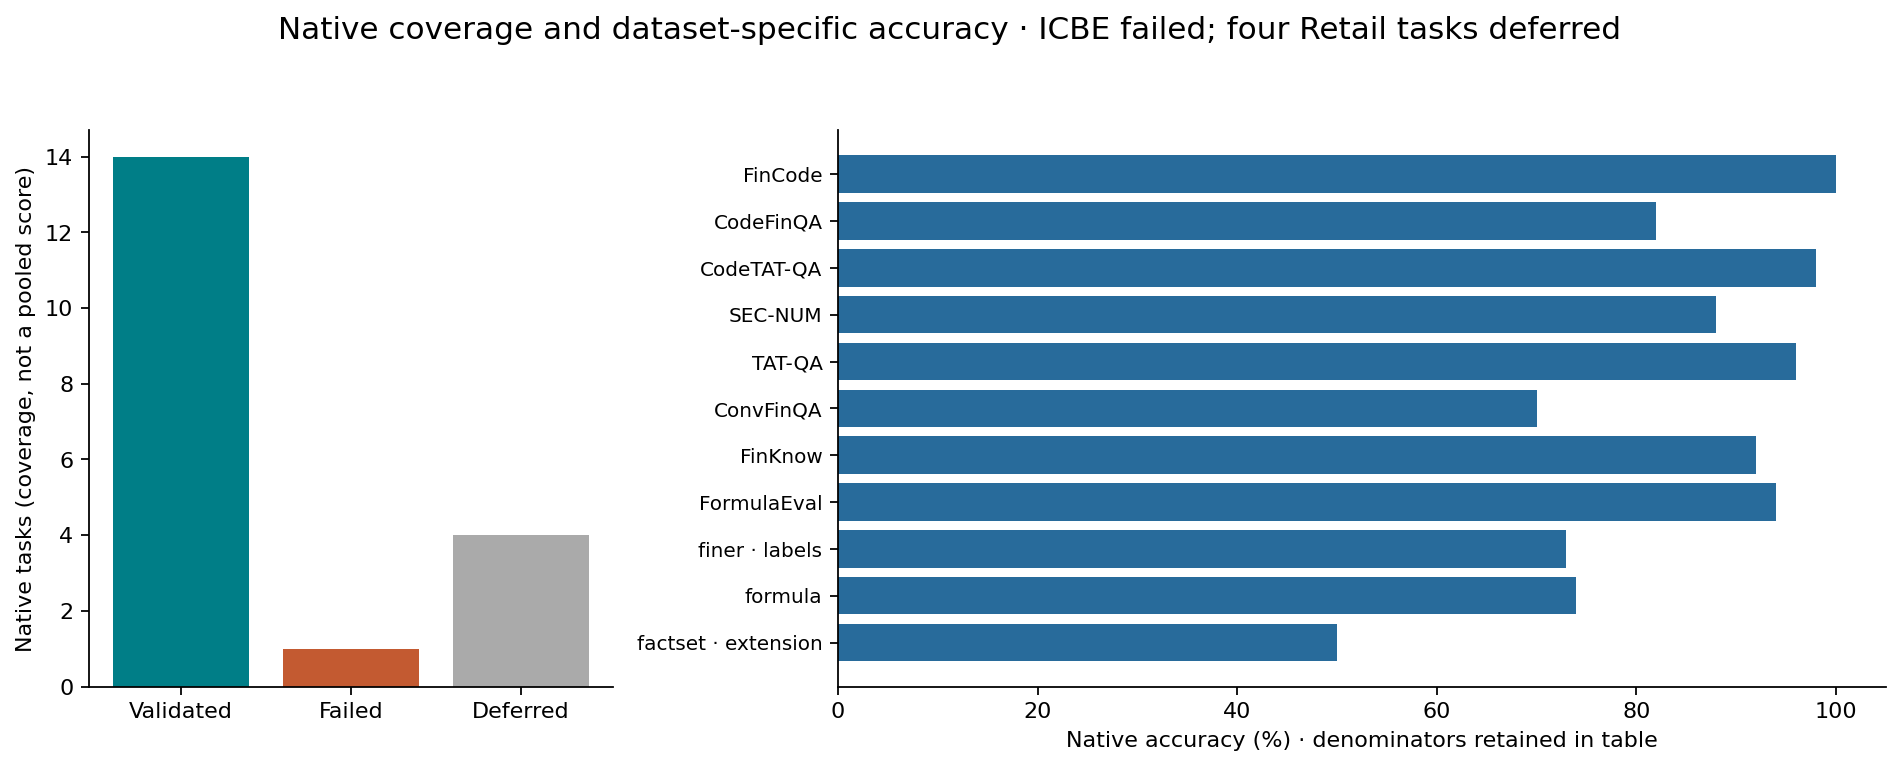

In [8]:
for name in ["contribution_contrasts", "recovery", "reliability_costs", "baseline_sensitivity", "diagnostic_examples", "native_coverage_reasoning"]:
    display(Image(filename=str(ASSETS / f"{name}.png")))

## Claim limits and source artifacts

There are three purposively selected blocks, one LLM realization per condition and dependent daily observations. The primary window may have been manually inspected before this evaluation. No day-level significance tests, population intervals, real-world causal claims, model-weight learning claims or practical-superiority threshold are supported. Action divergence can include independent model variation; no frozen-history ablation isolates the effect of history. Native accuracy denominators, the ICBE failure, missing values and deferred tasks remain explicit.

The [claim-to-artifact map](../docs/results/stage6/claim_map.csv), [public artifact manifest](../docs/results/stage6/artifact_manifest.json), [completed Stage 6 checkpoint](../docs/STAGE6_EXECUTION.md) and [frozen preparation/method plan](../docs/STAGE6_PREPARATION.md) provide the traceable results and qualifications.